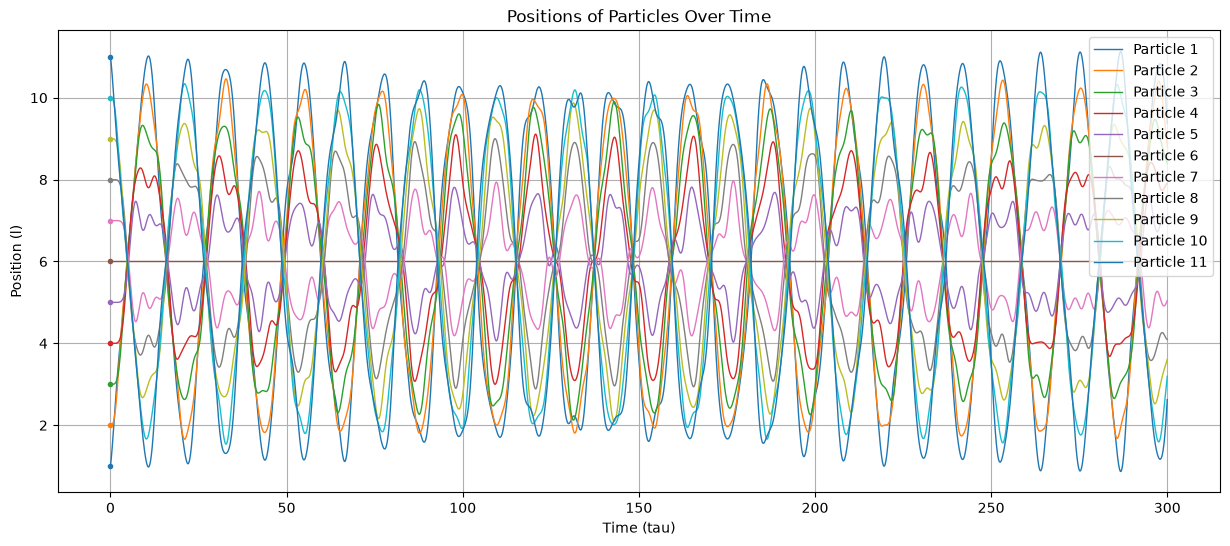

In [38]:
"""
Tasks (a):  Plot the positions ri(t) for t in [300] tau.

"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pyparsing import line

"""
1. Set up the parameters;
"""

k = 1
m = 1
l = 1
epsilon = k * l**2                                      # Energy unit for the harmonic chain
tau = np.sqrt(m / k)                                    # Time unit for the harmonic chain

N = 11                                                  # Number of beads in the chain
t = 300                                                 # Total time in tau
dt = 0.01                                               # Time step in tau
n = int(round(t / dt))                                  # Number of time steps

x_0 = np.array([i for i in range (1, N+1)])             # Initial position
p_0 = np.zeros(N)                                       # Initial momentum
p_0[0] = np.sqrt(0.5 * m * epsilon)             
p_0[N-1] = -np.sqrt(0.5 * m * epsilon)


"""
2. Force functions for the particles;
"""

def F_1(x1, x2):
    # force function for the first particle
    return k * (x2 - x1)

def F_i(x1, x2, x3):
    # force function for intermediate particles
    return k * (x1 - 2 * x2 + x3)

def F_N(x1, x2):
    # force function for the last particle
    return k * (x1 - x2)


"""
3. Create the Verlet function to perform the simulation;
"""

def verlet(x_0, p_0, N, t, dt):
    # Molecular dynamics simulation using Velocity-Verlet algorithm

    # x_0 (array): initial positions of particles
    # p_0 (array): initial momenta of particles
    # N (int): number of particles
    # t (float): total simulation time
    # dt (float): time step

    n = int(round(t / dt))                                          # Number of time steps
    x = np.zeros((N, n + 1))                                        # Array to store positions of particles at each time step
    p = np.zeros((N, n + 1))                                        # Array to store momenta of particles at each time step
    p_ = np.zeros((N, n + 1))                                       # Array to store half-step momenta

    x[:, 0] = x_0                                                   # Set initial positions
    p[:, 0] = p_0                                                   # Set initial momenta
    p_[:, 0] = p_0                                                  # Set initial half-step momenta

    for j in range(n):
        # for each time step

        for i in range(N):
            # for each particle
            if i == 0:
                F = F_1(x[i, j], x[i + 1, j])                                   # Force on the first particle

            elif i == N - 1:
                F = F_N(x[i - 1, j], x[i, j])                                   # Force on the last particle

            else:
                F = F_i(x[i - 1, j], x[i, j], x[i + 1, j])                      # Force on intermediate particles

            p_[i, j + 1] = p[i, j] + 0.5 * dt * F                               # Update momentum at half step
            x[i, j + 1] = x[i, j] + dt * p_[i, j + 1] / m                       # Update position

        for i in range(N):
            # for each particle
            
            if i == 0:      
                F_whole = F_1(x[i, j + 1], x[i + 1, j + 1])                     # Calculate newforce for the first particle

            elif i == N - 1:
                F_whole = F_N(x[i - 1, j + 1], x[i, j + 1])                     # Calculate new force for the last particle
            
            else:
                F_whole = F_i(x[i - 1, j + 1], x[i, j + 1], x[i + 1, j + 1])    # Calculate new force for intermediate particles
            
            p[i, j + 1] = p_[i, j + 1] + 0.5 * dt * F_whole                     # Update momentum at full step
                    

    return x, p                                                                 # Return arrays of positions, momenta, and end-to-end distances


def plot_x(x, t, dt):
    # Plot the positions of the particles over time

    n = int(round(t / dt))                                          # Number of time steps
    time = np.linspace(0, t, n + 1)                                 # Time array

    plt.figure(figsize=(15, 6))
    for i in range(x.shape[0]):
        line, = plt.plot(time, x[i, :], label=f'Particle {i + 1}', linewidth=1)             # Plot positions of each particle over time
        plt.plot(time[0], x[i, 0], 'o', color=line.get_color(), markersize=3)               # Plot initial positions as dots
    
    plt.title('Positions of Particles Over Time')
    plt.xlabel('Time (tau)')
    plt.ylabel('Position (l)')
    plt.legend()
    plt.grid()
    plt.show()


"""
4. Run the simulation and plot the results.
"""

verlet_x, verlet_p = verlet(x_0, p_0, N, t, dt)
plot_x(verlet_x, t, dt)

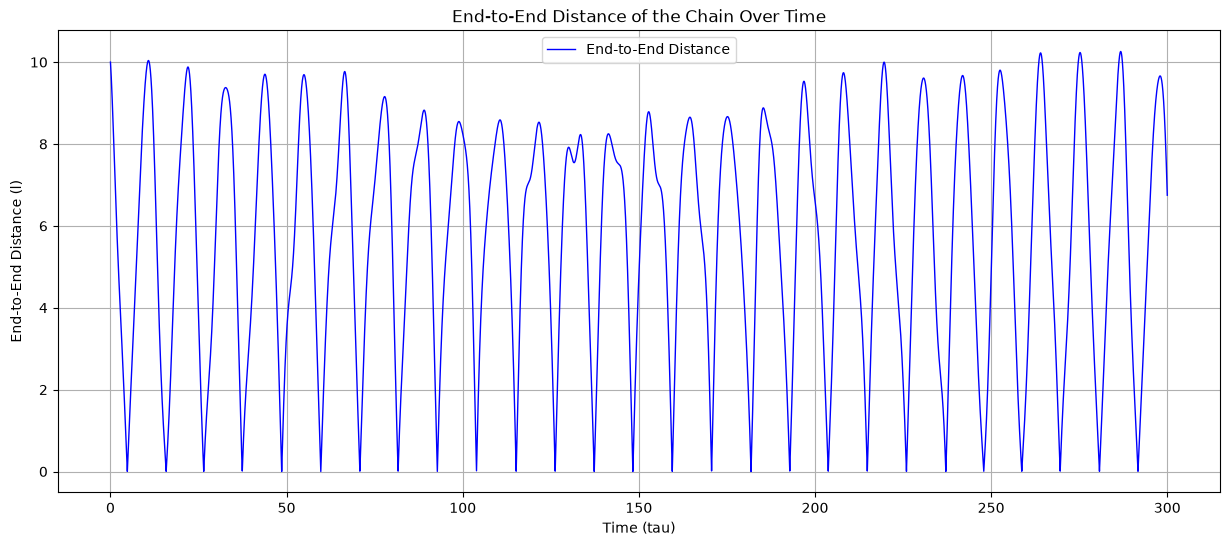

In [39]:

"""
Task (b)
1. Plot the end-to-end distance of the chain;
"""

def Re(x):
    # Calculate the end-to-end distance of the chain

    # x (array): positions of particles

    N, n_ = x.shape
    R = np.zeros(n_)                                             # Array to store the end-to-end distance

    for j in range(n_):
        R[j] = np.linalg.norm(x[N-1, j] - x[0, j])                  # Calculate end-to-end distance at each time step

    return R                                                        # Return the array of end-to-end distances


def plot_Re(R, t):
    # Plot the end-to-end distance of the chain over time

    time = np.linspace(0, t, len(R))                                # Time array

    plt.figure(figsize=(15, 6))
    plt.plot(time, R, label='End-to-End Distance', color='blue', linewidth=1)             # Plot end-to-end distance over time
    plt.title('End-to-End Distance of the Chain Over Time')
    plt.xlabel('Time (tau)')
    plt.ylabel('End-to-End Distance (l)')
    plt.legend()
    plt.grid()
    plt.show()

verlet_x, verlet_p = verlet(x_0, p_0, N, t, dt)
plot_Re(Re(verlet_x), t)

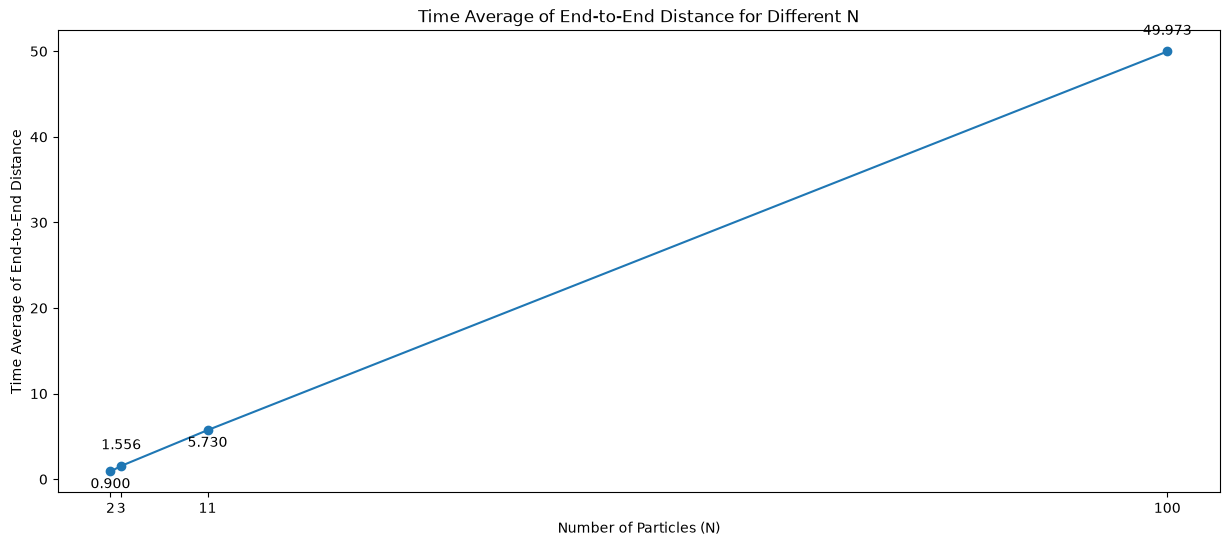

The time average of the end-to-end distance for N = [2, 3, 11, 100] is: [ 0.90033541  1.55620037  5.72990153 49.97337182]


array([ 0.90033541,  1.55620037,  5.72990153, 49.97337182])

In [40]:
"""
Task (b)
2. Compute the time average Re for N = 2, 3, 11, 100;
"""

"""
Create a function to calculate the time average of the end-to-end distance of the chain for different numbers of particles.
"""

def Re_avg(*args):
    # Calculate and plot the time average of the end-to-end distance of the chain

    # *args (array): positions of particles

    N = [x.shape[0] for x in args]                                      # Number of particles for each simulation
    Re_ = [Re(x) for x in args]                                         # Calculate end-to-end distance for each set of positions

    R_avg = np.array([np.mean(r) for r in Re_])                         # Calculate time average of end-to-end distance

    plt.figure(figsize=(15, 6))
    plt.plot(N, R_avg, marker='o')                                      # Plot time average of end-to-end distance for each N
    
    for i in range(len(N)):
        # Annotation for each point on the plot

        if i % 2 == 0:                                                  # Offset the text above the point for even indices and below for odd indices
            offset = -12
        else:
            offset = 12

        plt.annotate(f'{R_avg[i]:.3f}',                                 # 3 decimal places
                 (N[i], R_avg[i]),                                      # Coordinates
                 textcoords="offset points",                            # Offset text position
                 xytext=(0, offset),                                         # Offset in points
                 ha='center')                                           # Horizontal alignment
    plt.title('Time Average of End-to-End Distance for Different N')
    plt.xlabel('Number of Particles (N)')
    plt.ylabel('Time Average of End-to-End Distance')
    plt.xticks(N)
    plt.show()

    print(f'The time average of the end-to-end distance for N = {N} is: {R_avg}')  # Print the time average of the end-to-end distance
    return R_avg                                                        # Return the time average of the end-to-end distance


"""
Plot the time average of the end-to-end distance for N = 2, 3, 11, 100.
"""

x_values = {}

for N in [2, 3, 11, 100]:
    # Run the simulation for different numbers of particles and calculate the time average of the end-to-end distance

    
    x_0 = np.array([i for i in range(1, N+1)])              # Set initial positions based on different N
    p_0 = np.zeros(N)                                       # Set initial momenta based on different N
    p_0[0] = np.sqrt(0.5 * m * epsilon)                     
    p_0[N-1] = -np.sqrt(0.5 * m * epsilon)

    
    x_values[N], _ = verlet(x_0, p_0, N, t, dt)             # Store the positions and momenta for each N


Re_avg(*x_values.values())


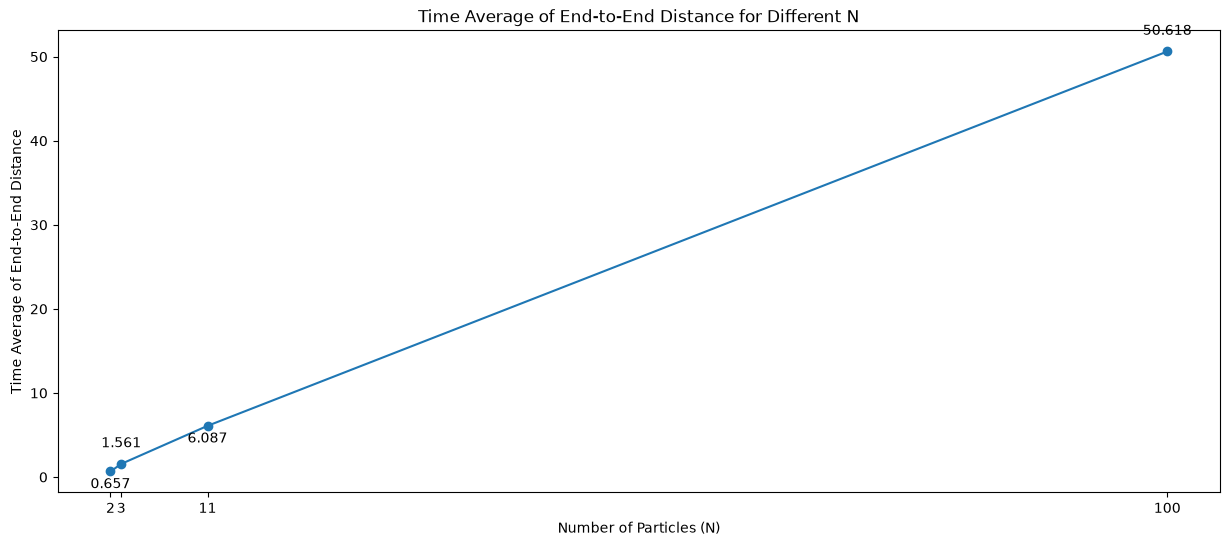

The time average of the end-to-end distance for N = [2, 3, 11, 100] is: [ 0.65722765  1.56136302  6.08671143 50.61846153]


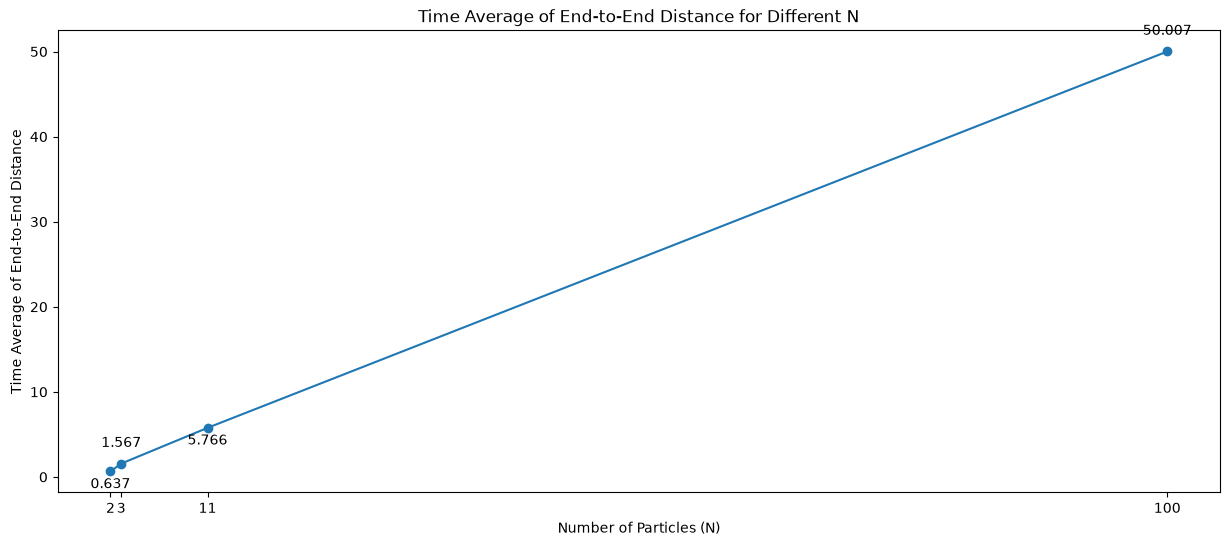

The time average of the end-to-end distance for N = [2, 3, 11, 100] is: [ 0.63685072  1.56710722  5.76622944 50.00663914]


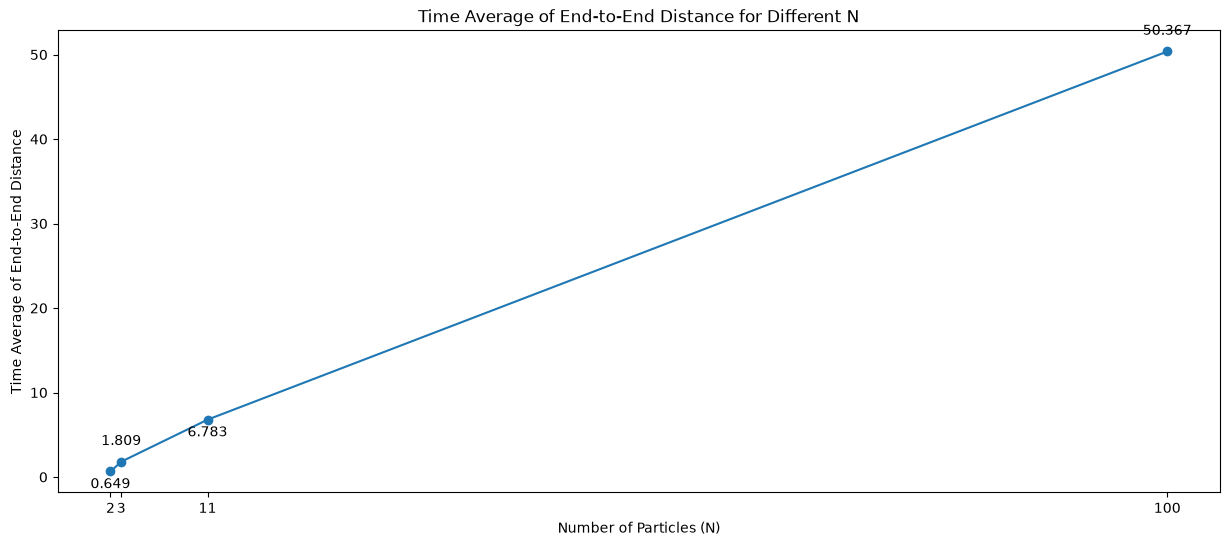

The time average of the end-to-end distance for N = [2, 3, 11, 100] is: [ 0.64909659  1.80910413  6.78277386 50.36652853]


In [41]:
"""
Task (b)
3. Repeat the simulation with random momenta distributed with variance m * epsilon.
"""

for a in range(3):

    x_values = {}

    for N in [2, 3, 11, 100]:
        # Run the simulation for different numbers of particles and calculate the time average of the end-to-end distance

        x_0 = np.array([i for i in range(1, N+1)])              # Set initial positions based on different N
        p_0 = np.random.normal(0, np.sqrt(m * epsilon), N)      # Set initial momenta with random values from a normal distribution with mean 0 and variance m * epsilon
    
        x_values[N], _ = verlet(x_0, p_0, N, t, dt)             # Store the positions and momenta for each N

    Re_avg(*x_values.values())
